# NYC Citi Bike Project
**ORIE 5530 · Modeling Under Uncertainty**: analysis of Citi Bike trip data for August 2026.

## 1. Data Cleaning

**Tasks**
- Clean the data by eliminating rides lasting more than **3 hours** and rides with **negative duration** (if any).
- Report the number of rows and columns **before cleaning** and the number of rides removed by each rule.
- Report the number of rides **retained**.
- Document any additional cleaning decisions.

### 1.1 Load the data
The month's trips are split across six CSV files, which we combine into a single DataFrame.

In [1]:
# Paths are relative to this notebook's folder, so it runs on anyone's machine.
# Setup: unzip 202608-citibike-tripdata.zip into this folder (see README).
from pathlib import Path
import pandas as pd

DATA_DIR = Path('202608-citibike-tripdata')

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data folder '{DATA_DIR}' not found next to this notebook. "
        "Get 202608-citibike-tripdata.zip (see README) and unzip it into this folder."
    )

pre_cleaned_df = pd.concat(
    [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
    ignore_index=True,
)

C:\Users\leoca\AppData\Local\Temp\ipykernel_30520\2120352414.py:15: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
C:\Users\leoca\AppData\Local\Temp\ipykernel_30520\2120352414.py:15: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
C:\Users\leoca\AppData\Local\Temp\ipykernel_30520\2120352414.py:15: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
C:\Users\leoca\AppData\Local\Temp\ipykernel_30520\2120352414.py:15: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i i

### 1.2 Explore the raw data

In [2]:
pre_cleaned_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E4A8132DACF670C3,electric_bike,2026-08-10 14:31:22.100,2026-08-10 14:37:37.034,E 33 St & 5 Ave,6322.01,W 24 St & 7 Ave,6257.03,40.747659,-73.984907,40.744876,-73.995299,member
1,8382768C05C30BB4,electric_bike,2026-08-10 08:04:28.348,2026-08-10 08:33:27.680,Emerson Pl & Myrtle Ave,4683.02,W 24 St & 7 Ave,6257.03,40.693631,-73.962236,40.744876,-73.995299,member
2,3A1C43832BBE4FCD,classic_bike,2026-08-08 19:36:32.350,2026-08-08 19:43:47.890,Broadway & E 19 St,5980.11,W 24 St & 7 Ave,6257.03,40.738290,-73.990060,40.744876,-73.995299,member
3,5C9BC6DFC4DEA183,electric_bike,2026-08-05 14:34:27.749,2026-08-05 14:46:23.526,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member
4,355579CC64D1BE20,electric_bike,2026-08-01 14:16:44.531,2026-08-01 14:29:39.539,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member


**Column notes**

| Column | Description | Missing (raw) |
|---|---|---:|
| `ride_id` | Unique ID for each ride | 0 |
| `rideable_type` | `electric_bike` or `classic_bike` | 0 |
| `started_at`, `ended_at` | Timestamps for when the ride started and ended | 0 |
| `start_station_name`, `start_station_id` | Name and ID of the start station | 2,870 / 2,870 |
| `start_lat`, `start_lng` | Latitude and longitude of the start station | 2,870 / 2,870 |
| `end_station_name`, `end_station_id` | Name and ID of the end station | 13,792 / 14,767 |
| `end_lat`, `end_lng` | Latitude and longitude of the end station | 14,733 / 14,733 |
| `member_casual` | `member` (Citi Bike member) or `casual` user | 0 |

**Potential action items**
- Remove long rides (3+ hours) and rides with negative duration.
- Investigate the missing location data.
- One-hot encode: `start_station_name`, `start_station_id`, `end_station_name`, `end_station_id`.
- Feature engineer: `rideable_type` (0 = electric bike, 1 = classic bike), `member_casual` (0 = member, 1 = casual).

In [3]:
pre_cleaned_df.isna().sum()

ride_id                   0
rideable_type             0
started_at                0
ended_at                  0
start_station_name     2870
start_station_id       2870
end_station_name      13792
end_station_id        14767
start_lat              2870
start_lng              2870
end_lat               14733
end_lng               14733
member_casual             0
dtype: int64

In [4]:
pre_cleaned_df.shape


(5246236, 13)

In [5]:
# Number of rows and columns before any cleaning
pre_cleaned_num_rows = len(pre_cleaned_df)
pre_cleaned_num_columns = len(pre_cleaned_df.columns)
print(f"The dataset has {pre_cleaned_num_rows:,} rows (number of rides) and {pre_cleaned_num_columns:,} columns prior to any data cleaning.")

The dataset has 5,246,236 rows (number of rides) and 13 columns prior to any data cleaning.


In [6]:
pre_cleaned_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5246236 entries, 0 to 5246235
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 520.3+ MB


In [7]:
pre_cleaned_df.describe()

,start_lat,start_lng,end_lat,end_lng
count,5.243366e+06,5.243366e+06,5.231503e+06,5.231503e+06
mean,4.073606e+01,-7.397052e+01,4.073599e+01,-7.397056e+01
std,4.157453e-02,3.022266e-02,4.162608e-02,3.029950e-02
min,4.061124e+01,-7.404079e+01,4.061124e+01,-7.408596e+01
25%,4.071107e+01,-7.399191e+01,4.071107e+01,-7.399193e+01
50%,4.073481e+01,-7.397840e+01,4.073455e+01,-7.397847e+01
75%,4.075963e+01,-7.395407e+01,4.075963e+01,-7.395407e+01
max,4.091239e+01,-7.383226e+01,4.091239e+01,-7.383226e+01


### 1.3 Pre-processing plan
- Eliminate rides lasting more than 3 hours and rides with negative durations.
- Handle the missing location data.
- Record the capacity (number of docks) of each station we model in Part I, entered manually from Google Maps.

(We originally planned to one-hot encode station names/IDs and encode `rideable_type` / `member_casual` as 0/1, but this was dropped: none of the analyses need it, since we filter on these columns directly.)

### 1.4 Filter by ride duration
There is no duration column, so we compute it by converting `started_at` and `ended_at` to datetimes and subtracting them.

**Cleaning decisions:** no rides had a negative duration, so Rule 1 removes nothing. Rides lasting exactly 0 minutes would be kept, since the rule only removes *negative* durations (there are none in this dataset). Rule 2 removes rides longer than 180 minutes.

In [8]:
df_dur = pre_cleaned_df.copy()
df_dur['started_at'] = pd.to_datetime(df_dur['started_at'])
df_dur['ended_at'] = pd.to_datetime(df_dur['ended_at'])
df_dur['duration_min'] = (df_dur['ended_at'] - df_dur['started_at']).dt.total_seconds() / 60  # duration in minutes

# Count rides removed by each rule (the two rules can't overlap)
num_negative = (df_dur['duration_min'] < 0).sum()    # Rule 1: negative duration
num_over_3hr = (df_dur['duration_min'] > 180).sum()  # Rule 2: longer than 3 hours

# Keep rides with non-negative duration that last at most 3 hours (0-minute rides are kept)
df_dur = df_dur[(df_dur['duration_min'] >= 0) & (df_dur['duration_min'] <= 180)]

df_num_rows = len(df_dur)
df_num_columns = len(df_dur.columns)
print(f"Rule 1 (negative duration): removed {num_negative:,} rides")
print(f"Rule 2 (longer than 3 hours): removed {num_over_3hr:,} rides")
print(f"Total removed: {num_negative + num_over_3hr:,} rides")
print(f"Retained: {df_num_rows:,} rides and {df_num_columns:,} columns (out of {pre_cleaned_num_rows:,} before cleaning)")

# Sanity check: removed + retained = original
assert num_negative + num_over_3hr + df_num_rows == pre_cleaned_num_rows

# Percent of the data filtered out
filtered_out_percent = (pre_cleaned_num_rows - df_num_rows) / pre_cleaned_num_rows * 100
print(f"Filtered out {filtered_out_percent:.2f}% of the data due to negative durations or rides lasting more than 3 hours.")

Rule 1 (negative duration): removed 0 rides
Rule 2 (longer than 3 hours): removed 6,020 rides
Total removed: 6,020 rides
Retained: 5,240,216 rides and 14 columns (out of 5,246,236 before cleaning)
Filtered out 0.11% of the data due to negative durations or rides lasting more than 3 hours.


### 1.5 Missing location data
We hoped to recover missing station names from the latitude/longitude columns, but whenever a station is missing, its coordinates are missing too. Since these rides are a small percentage of the data, we drop every ride missing **any** start or end location field (station name, station ID, latitude, or longitude). A station is needed to count arrivals and departures in Part I.

In [9]:
# Check: are there rides with a missing station name but available coordinates? (Answer: no)
missing_end_location_df = df_dur[df_dur['end_station_name'].isna() & ~df_dur['end_lat'].isna() & ~df_dur['end_lng'].isna()]
print(f"Rides with a missing end station name but known coordinates: {len(missing_end_location_df)}")

# Count rides missing any location field (name, ID, lat, or lng) on each side.
# A ride can be missing both start and end info, so we count unique rides, not start + end.
loc_cols = [f'{s}_{c}' for s in ['start', 'end']
            for c in ['station_name', 'station_id', 'lat', 'lng']]
missing_start = df_dur[loc_cols[:4]].isna().any(axis=1)
missing_end = df_dur[loc_cols[4:]].isna().any(axis=1)
missing_any = missing_start | missing_end

print(f"Rides missing start location data: {missing_start.sum():,}")
print(f"Rides missing end location data:   {missing_end.sum():,}")
print(f"Rides missing both:                {(missing_start & missing_end).sum():,}")
print(f"Rides missing any location data:   {missing_any.sum():,} ({missing_any.mean() * 100:.2f}% of rides)")

# This cell only inspects df_dur; the actual drop happens in the next cell.

Rides with a missing end station name but known coordinates: 0
Rides missing start location data: 2,856
Rides missing end location data:   12,552
Rides missing both:                476
Rides missing any location data:   14,932 (0.28% of rides)


In [10]:
# Drop rides with missing location data (loc_cols is defined in the cell above).
# Reads from df_dur and writes to df_clean, so rerunning this cell always gives the same result.
# .copy() so df_clean is its own DataFrame, not a view of df_dur.
df_clean = df_dur.dropna(subset=loc_cols).copy()

clean_num_rows, clean_num_columns = df_clean.shape
num_missing_location = len(df_dur) - clean_num_rows
pct_dropped = num_missing_location / len(df_dur) * 100

print(f"Removed {num_missing_location:,} rides with missing location data ({pct_dropped:.2f}%).")
print(f"Final cleaned dataset: {clean_num_rows:,} rows (number of rides) and {clean_num_columns} columns.")

# Sanity check: matches the count from the cell above
assert num_missing_location == missing_any.sum()

Removed 14,932 rides with missing location data (0.28%).
Final cleaned dataset: 5,225,284 rows (number of rides) and 14 columns.


### 1.6 Station capacity (number of docks)
The trip data doesn't include how many docks each station has, which we need as the Markov chain's capacity $C$ (state space $\{0, 1, \ldots, C\}$).

We look up each chosen station's number of docks on **Google Maps** and enter it by hand in `STATION_CAPACITY` below. Only the stations we model need a capacity. When we pick the remaining stations, add them to the dictionary.

**Caveat:** Google Maps shows the station's current dock count, which may differ slightly from August 2026.

In [11]:
# Station capacities (number of docks), entered manually from Google Maps.
# Keys must match the station name exactly as it appears in the trip data.
STATION_CAPACITY = {
    '7 Ave & Central Park South': 70,
    '55 Ave & Center Blvd': 24,
    'Roosevelt Island Tramway': 36
}

for station, capacity in STATION_CAPACITY.items():
    # Check each name exists in the data, so a typo fails here instead of later
    assert (df_clean['start_station_name'] == station).any(), f"Station not found in data: {station}"
    print(f"{station}: {capacity} docks")

7 Ave & Central Park South: 70 docks
55 Ave & Center Blvd: 24 docks
Roosevelt Island Tramway: 36 docks


## 2. Warm-Up Questions
1. Using the start and end times, compute each ride's duration in minutes and plot a histogram of ride durations.
2. What is the expected ride duration (the average ride duration)? What is the empirical variance of ride duration? What is the probability that a ride lasts more than 20 minutes?
3. What is the probability that a ride lasts more than 20 minutes conditional on the user being a Citi Bike member?
4. Suppose that a ride lasts more than 25 minutes. What is the probability that this ride belongs to a Citi Bike member?
5. What is the expected ride duration of an electric bike? What is the expected ride duration of a classic bike?
6. Suppose that a ride lasts less than 10 minutes. What is the probability that it uses an electric bike? What is the probability that it uses a classic bike? Comment on the results.

### Q1. Histogram of ride durations

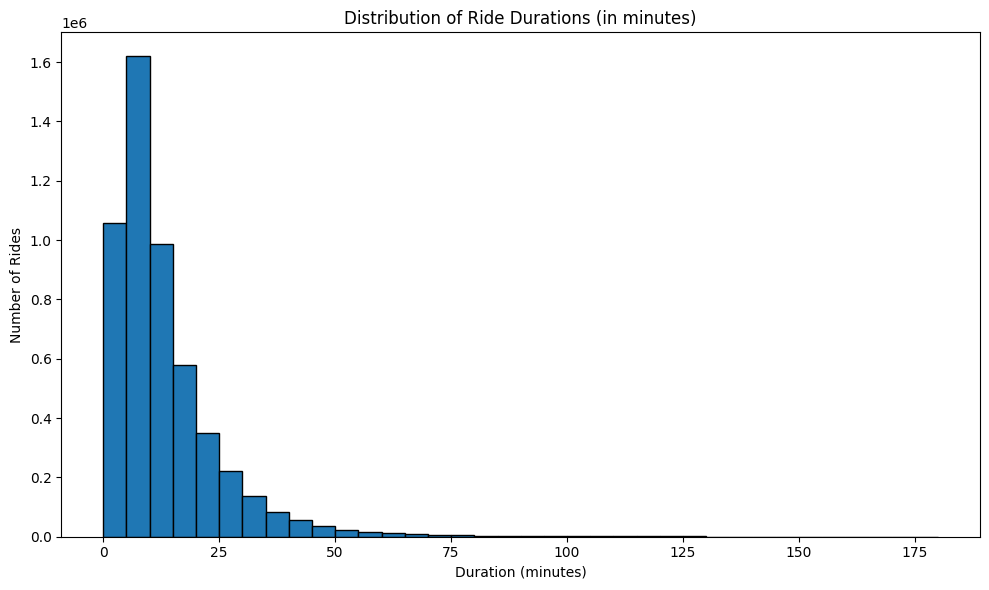

Median: 9.76 min | under 15 min: 70% | under 30 min: 92% | over 60 min: 1.1%


In [12]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(df_clean['duration_min'], bins=np.arange(0, 181, 5), edgecolor='black')

ax.set_title('Distribution of Ride Durations (in minutes)')
ax.set_xlabel('Duration (minutes)')
ax.set_ylabel('Number of Rides')
plt.tight_layout()
plt.show()

# Summary of the shape (used in the interpretation below)
d = df_clean['duration_min']
print(f"Median: {d.median():.2f} min | under 15 min: {(d < 15).mean():.0%} | under 30 min: {(d < 30).mean():.0%} | over 60 min: {(d > 60).mean():.1%}")

**Interpretation:** the distribution is strongly right-skewed. Most rides are short (median ≈ 9.8 min; about 70% under 15 min and 92% under 30 min), with a long, thin tail out to the 3-hour cutoff (about 1% of rides last over an hour). Citi Bike is mostly used for short point-to-point trips.

### Q2. Expected duration, variance, and P(duration > 20 min)

In [13]:
# Expected (average) ride duration
avg_duration_min = df_clean['duration_min'].mean()
# Empirical variance of ride duration
empirical_variance = df_clean['duration_min'].var()
# Probability that a ride lasts more than 20 minutes
prob_duration_over_20 = len(df_clean[df_clean['duration_min'] > 20]) / len(df_clean)

print(f"Average ride duration: {avg_duration_min:.2f} minutes")
print(f"Empirical variance of ride duration: {empirical_variance:.2f}")
print(f"Probability of ride lasting more than 20 minutes: {prob_duration_over_20:.2f}")

Average ride duration: 13.41 minutes
Empirical variance of ride duration: 157.22
Probability of ride lasting more than 20 minutes: 0.19


**Interpretation:** the mean (13.41 min) is well above the median (≈ 9.8 min), which confirms the right skew: a small number of long rides pull the average up. The variance of 157.22 min² (standard deviation ≈ 12.5 min) is large relative to the mean, so durations vary a lot from ride to ride. About 1 in 5 rides lasts more than 20 minutes.

### Q3. P(duration > 20 min | member)

In [14]:
members = df_clean[df_clean['member_casual'] == 'member']
prob_greater_than_20_given_member = (members['duration_min'] > 20).mean()
print(f"Probability of ride lasting more than 20 minutes given the user is a Citi Bike member: {prob_greater_than_20_given_member:.2f}")

casuals = df_clean[df_clean['member_casual'] == 'casual']
print(f"For comparison, casual riders: {(casuals['duration_min'] > 20).mean():.2f}")

Probability of ride lasting more than 20 minutes given the user is a Citi Bike member: 0.15
For comparison, casual riders: 0.32


**Interpretation:** members are less likely to take long rides (0.15) than riders overall (0.19), and much less likely than casual riders (≈ 0.32). This fits members using the system for short, routine trips such as commuting, while casual riders take more leisure rides.

### Q4. P(member | duration > 25 min)

In [15]:
rides_longer_than_25_min = len(df_clean[df_clean['duration_min'] > 25])  # rides lasting more than 25 minutes
riders_longer_than_25_min_and_member = len(df_clean[(df_clean['duration_min'] > 25) & (df_clean['member_casual'] == 'member')])  # ...that also belong to a member
prob_member_given_long_ride = riders_longer_than_25_min_and_member / rides_longer_than_25_min
print(f"Probability of being a Citi Bike member given the ride lasts more than 25 minutes: {prob_member_given_long_ride:.2f}")
print(f"For comparison, share of ALL rides taken by members: {(df_clean['member_casual'] == 'member').mean():.2f}")

Probability of being a Citi Bike member given the ride lasts more than 25 minutes: 0.60
For comparison, share of ALL rides taken by members: 0.79


**Interpretation:** members take about 79% of all rides but only 60% of rides longer than 25 minutes, so long rides over-represent casual users. Members are still the majority of long rides, simply because they take so many more rides in total. This is Bayes' rule at work: $P(\text{member} \mid > 25)$ depends on both how long members ride and how common members are.

### Q5. Expected duration by bike type

In [16]:
avg_ride_duration_electric = df_clean[df_clean['rideable_type'] == 'electric_bike']['duration_min'].mean()
avg_ride_duration_classic = df_clean[df_clean['rideable_type'] == 'classic_bike']['duration_min'].mean()
print(f"Expected ride duration of an electric bike: {avg_ride_duration_electric:.2f} minutes")
print(f"Expected ride duration of a classic bike: {avg_ride_duration_classic:.2f} minutes")
print(f"Medians: electric {df_clean.loc[df_clean['rideable_type'] == 'electric_bike', 'duration_min'].median():.2f} min, classic {df_clean.loc[df_clean['rideable_type'] == 'classic_bike', 'duration_min'].median():.2f} min")

Expected ride duration of an electric bike: 13.36 minutes
Expected ride duration of a classic bike: 13.54 minutes
Medians: electric 9.90 min, classic 9.32 min


**Interpretation:** the two averages are almost identical (13.36 vs 13.54 min, a difference of about 0.2 min), and the medians are also close. Bike type has very little effect on how long a ride lasts.

### Q6. P(bike type | duration < 10 min)

In [17]:
short_rides = df_clean[df_clean['duration_min'] < 10]
prob_electric_given_short_ride = (short_rides['rideable_type'] == 'electric_bike').mean()
prob_classic_given_short_ride = (short_rides['rideable_type'] == 'classic_bike').mean()
print(f"Probability of using an electric bike given the ride lasts less than 10 minutes: {prob_electric_given_short_ride:.2f}")
print(f"Probability of using a classic bike given the ride lasts less than 10 minutes: {prob_classic_given_short_ride:.2f}")

# For comparison (used in the comment below): bike-type share across ALL rides,
# and how often each bike type's rides are short
electric_share_all = (df_clean['rideable_type'] == 'electric_bike').mean()
prob_short_given_electric = (df_clean.loc[df_clean['rideable_type'] == 'electric_bike', 'duration_min'] < 10).mean()
prob_short_given_classic = (df_clean.loc[df_clean['rideable_type'] == 'classic_bike', 'duration_min'] < 10).mean()
print(f"Share of all rides on an electric bike: {electric_share_all:.2f}")
print(f"P(ride < 10 min | electric) = {prob_short_given_electric:.2f},  P(ride < 10 min | classic) = {prob_short_given_classic:.2f}")

Probability of using an electric bike given the ride lasts less than 10 minutes: 0.72
Probability of using a classic bike given the ride lasts less than 10 minutes: 0.28
Share of all rides on an electric bike: 0.73
P(ride < 10 min | electric) = 0.51,  P(ride < 10 min | classic) = 0.53


**Comment:** at first glance, 72% of short rides are on e-bikes, which might suggest riders prefer e-bikes for short trips. But e-bikes make up about 73% of *all* rides, so 0.72 mostly reflects the fleet mix, not a preference. Looking at it the other way, about half of e-bike rides (0.51) and half of classic rides (0.53) are under 10 minutes, so a ride being short tells us almost nothing about its bike type. This shows why a conditional probability should be compared against the base rate before drawing conclusions.

## 3. Part I: Modeling Citi Bike Stations Using Markov Chains

**Goal:** model the number of available bikes at a station as a Markov chain. For example, if a station near Central Park has 20 bikes early on a Monday morning, estimate how many will be available later that morning and understand the station's longer-run behavior.

### Setup
- **Stations:** choose **three popular Citi Bike stations** in NYC with substantial activity, and **explain the selection**.
- **Time blocks:** split the day into **two blocks** (e.g., morning and evening), **weekdays only**. Specify the hours in each block.
- **Time step:** discretize each block into periods of **5 or 10 minutes** (or justify another choice).
- **Model:** the number of available bikes at a station is a **discrete-time Markov chain**.
  - Natural state space: $\{0, 1, \ldots, C\}$, where $C$ is the station's capacity (number of docks, from Google Maps).
  - Estimate transitions from the **arrivals and departures** in each time interval.
  - Estimate a **separate transition model for each station × time block** (3 stations × 2 blocks = 6 models), using the **August weekday** data.

This is open-ended: make and justify your own modeling choices, state assumptions clearly, and explain how the model connects to the data. A different formulation is allowed if you explain why it's appropriate and how it addresses the objective.

### Report requirements
1. **Model definition.** Define the state space, time step, and transition mechanism. Explain how the Markov chain is estimated from the data and how situations not fully specified by the observations are handled.
2. **Transition matrices.** Present the estimated transition matrices (or a concise representation if they're large). Explain how they differ across stations and time blocks.
3. **Stationary distributions.** Compute and interpret them. Discuss whether a stationary distribution exists and is unique for the model; if not, explain why and give an appropriate alternative summary.
4. **Interpretation.** Discuss what the results imply about station activity and bike availability, the long-run behavior of each station, and any limitations of these conclusions.

### Checklist
- [ ] 3 stations chosen, with justification
- [ ] 2 weekday time blocks defined (hours specified)
- [ ] Time step chosen (5 / 10 min, or justified alternative)
- [ ] Station capacities (docks) recorded
- [ ] State space, transition mechanism, and estimation method defined
- [ ] Handling of unobserved / unspecified transitions explained
- [ ] 6 transition matrices estimated and presented
- [ ] Differences across stations and blocks discussed
- [ ] Stationary distributions computed; existence and uniqueness discussed
- [ ] Implications, long-run behavior, and limitations discussed

### 3.1 Choosing the stations
Most common start/end station pairs on weekdays, used to find busy stations.

In [18]:
# trips that started on a weekday (Monday = 0, ..., Sunday = 6)
dfleft_weekday_clean = df_clean[df_clean['started_at'].dt.dayofweek <5].copy()
# trips that ended on a weekday
dfreturned_weekday_clean = df_clean[df_clean["ended_at"].dt.dayofweek <5].copy()

In [19]:
# Top 10 start/end station pairs by number of weekday trips
dfreturned_weekday_clean.groupby(['start_station_name', 'end_station_name']).size().sort_values(ascending=False).head(10)

start_station_name          end_station_name          
7 Ave & Central Park South  7 Ave & Central Park South    1329
Central Park S & 6 Ave      Central Park S & 6 Ave        1104
Vernon Blvd & 50 Ave        55 Ave & Center Blvd           716
N 6 St & Bedford Ave        S 2 St & Kent Ave              684
55 Ave & Center Blvd        Vernon Blvd & 50 Ave           627
Roosevelt Island Tramway    Roosevelt Island Tramway       619
Soissons Landing            Soissons Landing               605
N 6 St & Bedford Ave        S 4 St & Wythe Ave             604
S 2 St & Kent Ave           N 6 St & Bedford Ave           577
S 4 St & Wythe Ave          N 6 St & Bedford Ave           565
dtype: int64

### 3.2 Worked example: net change at Station 1 (7 Ave & Central Park South)
**Goal:** understand how the number of bikes at the dock changes over time. The trip data doesn't record how many bikes are at a station, so we track the **net change** in each 10-minute window instead:

$$\text{net change} = \#\text{returns} - \#\text{rentals}$$

This first pass uses weekday trips before noon.

**Station facts**
- **Capacity:** 70 docks (from Google Maps; used as $C$ in the Markov chain, see `STATION_CAPACITY` in section 1.6)
- Snapshot from the Citi Bike map when we looked: 8 classic bikes and 16 e-bikes available (a live count, not used in the model)

In [20]:
#dataset with trips that started on a weekday and before noon
dfleft_weekday_clean = df_clean[(df_clean['started_at'].dt.dayofweek <5) & (df_clean["started_at"].dt.hour < 12)].copy()
#dataset with trips that ended on a weekday and before noon
dfreturned_weekday_clean = df_clean[(df_clean["ended_at"].dt.dayofweek <5) & (df_clean["ended_at"].dt.hour < 12)].copy()

#filtering to Central Park (start and end station)
StartedAt_Station1 = dfleft_weekday_clean[dfleft_weekday_clean['start_station_name'] == '7 Ave & Central Park South'].copy() # Gets all the Users that rented the bike
EndedAt_Station1 = dfreturned_weekday_clean[dfreturned_weekday_clean['end_station_name'] == '7 Ave & Central Park South'].copy() # Gets all the Users that returned the bike


#so far, trips that started/ended on a weekday and before noon, and the start and end station was 7th Ave & Central Park

#looking at all the start times for all trips (all trips which started on a weekday, before noon, and at Central Park)
#we round each trip started_at time to the 10 min mark (ie. 8:03 becomes 8:00)
left_counts = StartedAt_Station1["started_at"].dt.floor("10min").value_counts() # Creates different buckets for 10 min interval in a given day and counts each one that repeats

#looking at all the end times for all trips (all trips which started on a weekday, before noon, and at Central Park)
#we round each trip ended_at time to the 10 min mark (ie. 8:09 becomes 8:00)
return_counts = EndedAt_Station1["ended_at"].dt.floor("10min").value_counts()

#we now have for all trips which started/ended on a weekday, before noon, and at Central Park
#the number of trips for every 10 min window per day

#we then calculate the net change by (net change = # trips returned - # trips that left per 10 min window per day)
net_change = return_counts.subtract(left_counts, fill_value=0).sort_index() # Subtracts returned bikes - rented_bikes, if both dont exists skip, if left or right unknown treat it as zero 
net_change

2026-08-03 00:00:00   -4.0
2026-08-03 00:10:00    0.0
2026-08-03 00:20:00   -1.0
2026-08-03 01:20:00    0.0
2026-08-03 01:30:00   -1.0
                      ... 
2026-08-31 11:10:00   -5.0
2026-08-31 11:20:00    2.0
2026-08-31 11:30:00    0.0
2026-08-31 11:40:00   -4.0
2026-08-31 11:50:00    5.0
Name: count, Length: 952, dtype: float64

**Note:** this first version (v1) only includes 10-minute windows with at least one rental or return. Windows where nothing happened are skipped, so they don't count toward $P(\text{net change} = 0)$. Section 3.4 adds them back.

In [21]:
net_counts = net_change.value_counts().sort_index()
net_table = net_counts.rename_axis("net_change").reset_index(name="count")
net_table["probability"] = net_table["count"] / net_table["count"].sum()
net_table

,net_change,count,probability
0,-10.0,1,0.001050
1,-9.0,3,0.003151
2,-8.0,2,0.002101
3,-7.0,6,0.006303
4,-6.0,9,0.009454
5,-5.0,19,0.019958
6,-4.0,26,0.027311
7,-3.0,41,0.043067
8,-2.0,75,0.078782
9,-1.0,168,0.176471


### 3.3 Reusable station functions
The functions below wrap the steps above so they can be repeated for any station and time block:
- `station_net_change(df, station, start_hour, end_hour)`: net change per 10-minute window
- `net_change_distribution(net_change)`: empirical probability of each net change value
- `station_analysis(df, station, start_hour, end_hour)`: both of the above at once

In [22]:
def station_net_change(df, station, start_hour=0, end_hour=12, weekdays_only=True, freq="10min"):
    """Net change (returns - rentals) at one station for each time window.

    station:     exact station name, e.g. '7 Ave & Central Park South'
    start_hour:  include trips from this hour (inclusive)
    end_hour:    up to this hour (exclusive), e.g. 0-12 = morning, 12-24 = afternoon/evening
    freq:        window size, e.g. "10min", "15min", "1h"
    """
    start_t, end_t = df["started_at"], df["ended_at"]

    left_mask = (df["start_station_name"] == station) & start_t.dt.hour.between(start_hour, end_hour - 1)
    returned_mask = (df["end_station_name"] == station) & end_t.dt.hour.between(start_hour, end_hour - 1)
    if weekdays_only:
        left_mask &= start_t.dt.dayofweek < 5
        returned_mask &= end_t.dt.dayofweek < 5

    # count rentals / returns in each window (per date)
    left_counts = start_t[left_mask].dt.floor(freq).value_counts()
    return_counts = end_t[returned_mask].dt.floor(freq).value_counts()

    # returns - rentals; a window missing from one side counts as 0
    return return_counts.subtract(left_counts, fill_value=0).sort_index()


def net_change_distribution(net_change):
    """Empirical probability table of the net change values."""
    net_counts = net_change.value_counts().sort_index()
    table = net_counts.rename_axis("net_change").reset_index(name="count")
    table["probability"] = table["count"] / table["count"].sum()
    return table


def station_analysis(df, station, start_hour=0, end_hour=12, weekdays_only=True, freq="10min"):
    """Convenience wrapper: returns (net_change series, probability table)."""
    net_change = station_net_change(df, station, start_hour, end_hour, weekdays_only, freq)
    return net_change, net_change_distribution(net_change)


net_change_s1, net_table_s1 = station_analysis(df_clean, "7 Ave & Central Park South", start_hour=0, end_hour=12)
net_table_s1

,net_change,count,probability
0,-10.0,1,0.001050
1,-9.0,3,0.003151
2,-8.0,2,0.002101
3,-7.0,6,0.006303
4,-6.0,9,0.009454
5,-5.0,19,0.019958
6,-4.0,26,0.027311
7,-3.0,41,0.043067
8,-2.0,75,0.078782
9,-1.0,168,0.176471


In [23]:
# for each net change value seen in station_net_change's output,
# estimate the probability it happens:
# (# of windows with a net change of ___) / (total # of windows with any activity)
# windows are 10-min slots on August weekdays in the chosen hour range
#ie) for Central Park August, there are 952 10 minute time blocks in August that had activity
# for net change, this could be -10
#therefore probability of a net change of -10 happening is 1/952 = 0.105%
station_net_change_s1 = station_net_change(df_clean, "7 Ave & Central Park South", start_hour=0, end_hour=12)
station_net_change_dist_s1 = net_change_distribution(station_net_change_s1)
station_net_change_dist_s1

,net_change,count,probability
0,-10.0,1,0.001050
1,-9.0,3,0.003151
2,-8.0,2,0.002101
3,-7.0,6,0.006303
4,-6.0,9,0.009454
5,-5.0,19,0.019958
6,-4.0,26,0.027311
7,-3.0,41,0.043067
8,-2.0,75,0.078782
9,-1.0,168,0.176471


### 3.4 Including windows with no activity (v2)
So far, the probability of each net change is

$$P(\text{net change} = k) = \frac{\#\text{ windows with net change } k}{\#\text{ windows with any activity}}$$

which leaves out 10-minute windows where nobody rented or returned a bike. But those windows are real steps of the Markov chain where the bike count stays the same. **We use v2**, which includes them:

$$P(\text{net change} = k) = \frac{\#\text{ windows with net change } k}{\#\text{ all 10-minute windows in the time block (August weekdays)}}$$

The denominator is then the same for every station within a time block.

In [24]:
# station_net_change_v2
# Same as station_net_change, except it also includes windows with no activity.
#
# What it does:
#   For one station and hour range (weekdays only by default), returns the net change
#   (returns - rentals) for EVERY 10-min window in the time block on every weekday of
#   the month, e.g. 21 weekdays x 72 windows = 1,512 windows for 0-12.
#   Windows with no rentals or returns get a net change of 0.
#
# Difference from v1:
#   v1 only returns windows with at least one rental or return (952 for station 1,
#   morning). Quiet windows are left out entirely.
#   v2 adds those quiet windows back as 0s, so:
#     - P(net change = 0) goes up (station 1 morning: now 0.460); all other probabilities go down
#     - the denominator is the same for every station within a time block (1,512)
#   Reasoning: the Markov chain takes a step every 10 min whether or not anything
#   happens, so quiet windows are real steps where the bike count stays the same.
#
# DECISION: we use v2 for the transition model, since quiet windows are real
#   10-minute steps where the bike count doesn't change.

def station_net_change_v2(df, station, start_hour=0, end_hour=12, weekdays_only=True, freq="10min"):
    """Net change (returns - rentals) at one station for every time window in the block,
    including windows with no activity (net change 0)."""
    start_t, end_t = df["started_at"], df["ended_at"]

    left_mask = (df["start_station_name"] == station) & start_t.dt.hour.between(start_hour, end_hour - 1)
    returned_mask = (df["end_station_name"] == station) & end_t.dt.hour.between(start_hour, end_hour - 1)
    if weekdays_only:
        left_mask &= start_t.dt.dayofweek < 5
        returned_mask &= end_t.dt.dayofweek < 5

    # count rentals / returns in each window (per date)
    left_counts = start_t[left_mask].dt.floor(freq).value_counts()
    return_counts = end_t[returned_mask].dt.floor(freq).value_counts()
    net_change = return_counts.subtract(left_counts, fill_value=0)

    # build every window in the time block for every day of the data's month
    # (uses the most common month, so a few trips from July 31 don't add an extra day)
    month = start_t.dt.to_period("M").mode()[0]
    days = pd.date_range(month.start_time, month.end_time.normalize(), freq="D")
    if weekdays_only:
        days = days[days.dayofweek < 5]
    all_windows = pd.DatetimeIndex([]).append([
        pd.date_range(day + pd.Timedelta(hours=start_hour),
                      day + pd.Timedelta(hours=end_hour),
                      freq=freq, inclusive="left")
        for day in days
    ])

    # windows with no rentals or returns get a net change of 0
    return net_change.reindex(all_windows, fill_value=0).astype(int)
station_net_change_v2_s1 = station_net_change_v2(df_clean, "7 Ave & Central Park South", start_hour=0, end_hour=12)
station_net_change_v2_s1


2026-08-03 00:00:00   -4
2026-08-03 00:10:00    0
2026-08-03 00:20:00   -1
2026-08-03 00:30:00    0
2026-08-03 00:40:00    0
                      ..
2026-08-31 11:10:00   -5
2026-08-31 11:20:00    2
2026-08-31 11:30:00    0
2026-08-31 11:40:00   -4
2026-08-31 11:50:00    5
Name: count, Length: 1512, dtype: int32

In [25]:
station_net_change_v2_dist_s1 = net_change_distribution(station_net_change_v2_s1)
station_net_change_v2_dist_s1

,net_change,count,probability
0,-10,1,0.000661
1,-9,3,0.001984
2,-8,2,0.001323
3,-7,6,0.003968
4,-6,9,0.005952
5,-5,19,0.012566
6,-4,26,0.017196
7,-3,41,0.027116
8,-2,75,0.049603
9,-1,168,0.111111


### 3.5 Building the transition matrix
**State:** the number of bikes at the station, $i \in \{0, 1, \ldots, C\}$, where $C$ is the station's capacity from `STATION_CAPACITY` (section 1.6). The matrix is $(C+1) \times (C+1)$.

**Inputs:** the station, the time block (start and end hour), and the station's capacity.

**Transition probabilities.** The trip data doesn't tell us how many bikes are at the station, so we can't count state-to-state moves directly. Instead, each $P_{ij}$ comes from the v2 net-change distribution:
- **Interior:** $P_{ij} = P(\text{net change} = j - i)$.
- **Empty boundary:** a net change that would take the station below 0 is counted as landing on 0 (no bikes left to rent): $P_{i0} = P(\text{net change} \le -i)$.
- **Full boundary:** a net change that would take it above $C$ is counted as landing on $C$ (no empty docks to return to): $P_{iC} = P(\text{net change} \ge C - i)$.

**Assumption:** the net-change distribution is the same no matter how many bikes are at the station, so every row is the same pattern shifted over by one (except near 0 and $C$).

In [26]:
# Station capacities (number of docks), entered manually from Google Maps.
# Keys must match the station name exactly as it appears in the trip data.
STATION_CAPACITY = {
    '7 Ave & Central Park South': 70,
    '55 Ave & Center Blvd': 24,
    'Roosevelt Island Tramway': 36
}

for station, capacity in STATION_CAPACITY.items():
    # Check each name exists in the data, so a typo fails here instead of later
    assert (df_clean['start_station_name'] == station).any(), f"Station not found in data: {station}"
    print(f"{station}: {capacity} docks")

7 Ave & Central Park South: 70 docks
55 Ave & Center Blvd: 24 docks
Roosevelt Island Tramway: 36 docks


In [27]:
def transition_matrix_construction(df, station, start_hour=7, end_hour=10, weekdays_only=True, freq="10min"):
    #net_change: for specified station and time block on weekdays only
    #we look at each 10 minute time block
    #and see what the net change is
    #uses v2, which includes windows with no activity (net change 0)
    net_change = station_net_change_v2(df, station, start_hour, end_hour, weekdays_only, freq)

    #for each net change, what is the probability it happens
    dist = net_change_distribution(net_change)  

    #look up the station's capacity (number of docks), entered manually in section 1.6
    station_capacity = STATION_CAPACITY[station]

    #+1 bc we need states 0, 1, ..., capacity (e.g. 70 docks -> 71 states, including 0 bikes)
    transition_matrix = np.zeros((station_capacity + 1, station_capacity + 1))

    #Pij 
    #number of windows with net change k
    #divided by 
    #total # of windows in time block (ie. 7am~10am)
    #this is in dist table (dist['probability'])

    p = dict(zip(dist['net_change'], dist['probability'])) #probability of each net change

    for i in range(station_capacity + 1): #for each starting state from 0 to station capacity
        for j in range(station_capacity + 1): #for end state from 0 to station capacity
            if j == 0: #if the new state is 0
                transition_matrix[i, j] = sum(prob for k, prob in p.items() if k <= -i) #add up all net_changes that leave with 0 bikes 
                #so in the first loop, in state i = 0, we look at all combinations of 0 -> 0, 0-> 1, ..., 0->capacity
                #if j=0
                #we calculate the sum of probabilities of all net_changes that is less than or equal to the original state
                #so even when i=1
                #when j=0
                #we sum the net probabilities <=-1 
            elif j == station_capacity: 
                #if j is full or meets station capacity
                #we calculate the sum of probabilities where net_change is greater than or equal to the station_capacity minus the current state
                transition_matrix[i, j] = sum(prob for k, prob in p.items() if k >= station_capacity - i)   # rise to station_capacity or above
            else:
                #retrieve the probability where net change is j-i
                transition_matrix[i, j] = p.get(j - i, 0)                                    # exact jump

    return transition_matrix


### 3.6 Transition matrices for each station and time block
| Time block | Hours | Steps per block |
|---|---|---:|
| Morning | 7am–10am | 18 |
| Evening | 4pm–7pm | 18 |

Each block uses all 21 August weekdays (21 × 18 = 378 ten-minute windows).

#### 7 Ave & Central Park South: morning (7–10am)

In [28]:
transition_matrix_central_park_morning_block = transition_matrix_construction(df_clean, "7 Ave & Central Park South", start_hour=7, end_hour=10)
P = pd.DataFrame(transition_matrix_central_park_morning_block)

P.index.name = "Current State"
P.columns.name = "Next State"

display(P.round(3))

Next State,0,1,2,3,4,5,6,7,8,9,...,61,62,63,64,65,66,67,68,69,70
Current State,,,,,,,,,,,,,,,,,,,,,
0,0.455,0.132,0.132,0.093,0.074,0.034,0.024,0.016,0.008,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.312,0.143,0.132,0.132,0.093,0.074,0.034,0.024,0.016,0.008,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,0.196,0.116,0.143,0.132,0.132,0.093,0.074,0.034,0.024,0.016,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,0.127,0.069,0.116,0.143,0.132,0.132,0.093,0.074,0.034,0.024,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,0.074,0.053,0.069,0.116,0.143,0.132,0.132,0.093,0.074,0.034,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.024,0.032,0.053,0.069,0.116,0.143,0.132,0.132,0.093,0.188
67,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.008,0.024,0.032,0.053,0.069,0.116,0.143,0.132,0.132,0.280
68,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.005,0.008,0.024,0.032,0.053,0.069,0.116,0.143,0.132,0.413


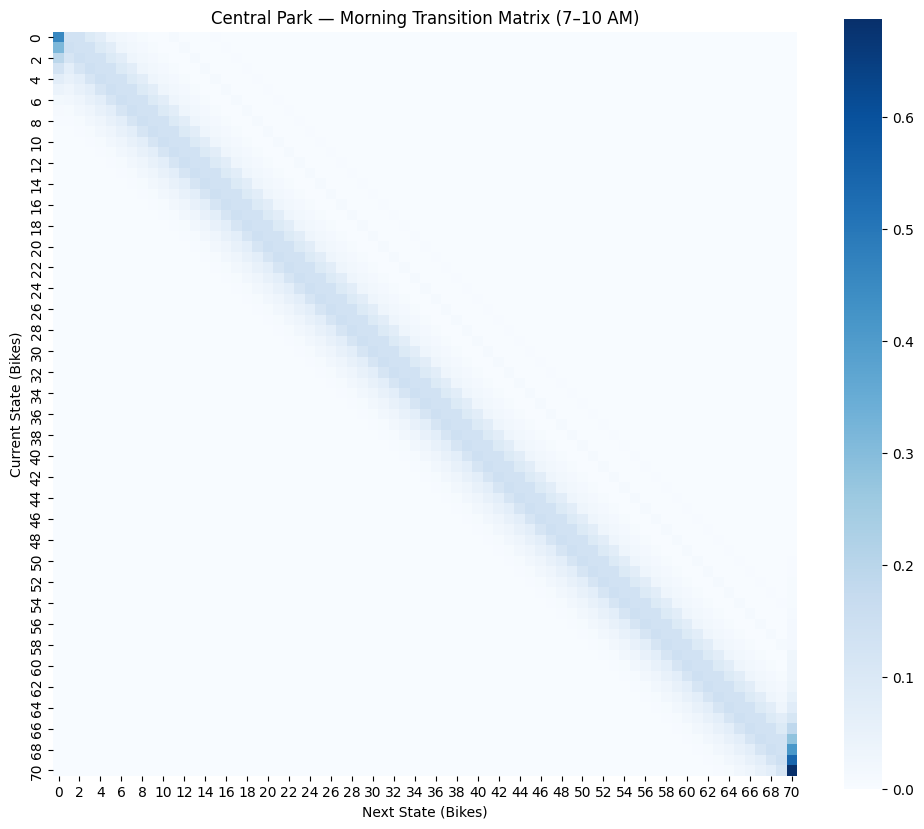

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

sns.heatmap(P, cmap="Blues", square=True)

plt.title("Central Park — Morning Transition Matrix (7–10 AM)")
plt.xlabel("Next State (Bikes)")
plt.ylabel("Current State (Bikes)")
plt.show()

#### 7 Ave & Central Park South: evening (4–7pm)

In [30]:
transition_matrix_central_park_evening_block = transition_matrix_construction(df_clean, "7 Ave & Central Park South", start_hour=16, end_hour=19)
P = pd.DataFrame(transition_matrix_central_park_evening_block)

P.index.name = "Current State"
P.columns.name = "Next State"

display(P.round(3))

Next State,0,1,2,3,4,5,6,7,8,9,...,61,62,63,64,65,66,67,68,69,70
Current State,,,,,,,,,,,,,,,,,,,,,
0,0.659,0.079,0.069,0.042,0.042,0.034,0.032,0.011,0.005,0.011,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.529,0.130,0.079,0.069,0.042,0.042,0.034,0.032,0.011,0.005,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,0.439,0.090,0.130,0.079,0.069,0.042,0.042,0.034,0.032,0.011,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,0.354,0.085,0.090,0.130,0.079,0.069,0.042,0.042,0.034,0.032,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,0.283,0.071,0.085,0.090,0.130,0.079,0.069,0.042,0.042,0.034,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.061,0.077,0.071,0.085,0.090,0.130,0.079,0.069,0.042,0.151
67,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.013,0.061,0.077,0.071,0.085,0.090,0.130,0.079,0.069,0.193
68,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.029,0.013,0.061,0.077,0.071,0.085,0.090,0.130,0.079,0.262


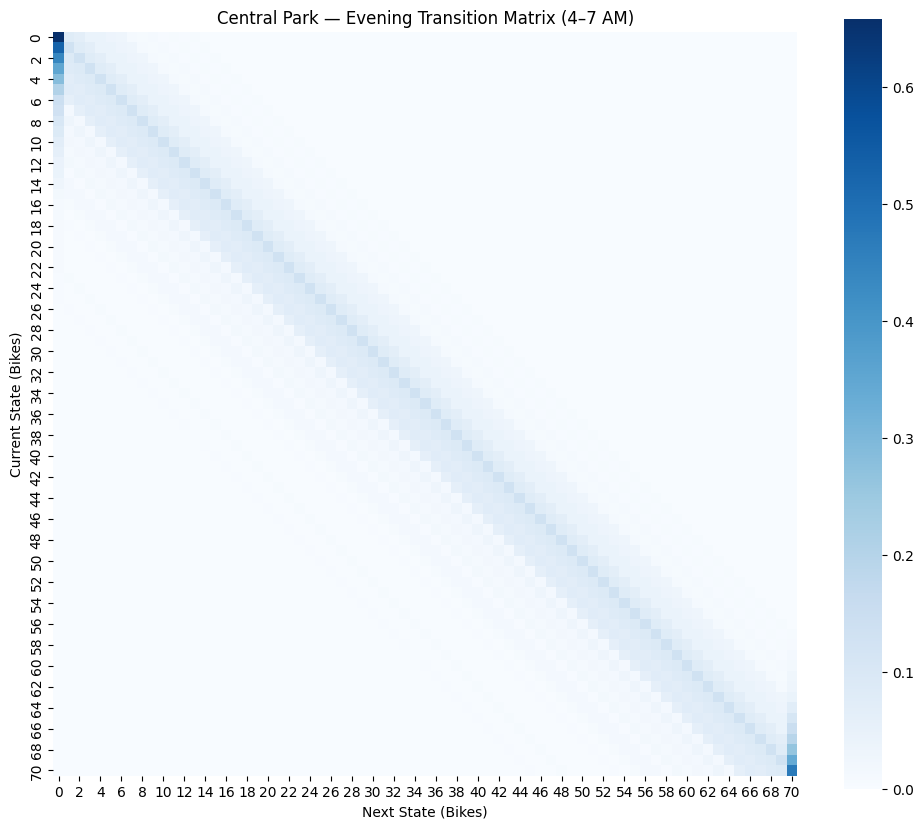

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

sns.heatmap(P, cmap="Blues", square=True)

plt.title("Central Park — Evening Transition Matrix (4–7 AM)")
plt.xlabel("Next State (Bikes)")
plt.ylabel("Current State (Bikes)")
plt.show()

#### 55 Ave & Center Blvd: morning (7–10am)

In [32]:
transition_matrix_55_ave_morning_block = transition_matrix_construction(df_clean, "55 Ave & Center Blvd", start_hour=7, end_hour=10)
P = pd.DataFrame(transition_matrix_55_ave_morning_block)

P.index.name = "Current State"
P.columns.name = "Next State"

display(P.round(3))

Next State,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
Current State,,,,,,,,,,,,,,,,,,,,,
0,0.831,0.124,0.026,0.013,0.003,0.000,0.003,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.458,0.373,0.124,0.026,0.013,0.003,0.000,0.003,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,0.222,0.235,0.373,0.124,0.026,0.013,0.003,0.000,0.003,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,0.090,0.132,0.235,0.373,0.124,0.026,0.013,0.003,0.000,0.003,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,0.026,0.063,0.132,0.235,0.373,0.124,0.026,0.013,0.003,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
5,0.005,0.021,0.063,0.132,0.235,0.373,0.124,0.026,0.013,0.003,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
6,0.003,0.003,0.021,0.063,0.132,0.235,0.373,0.124,0.026,0.013,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
7,0.000,0.003,0.003,0.021,0.063,0.132,0.235,0.373,0.124,0.026,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
8,0.000,0.000,0.003,0.003,0.021,0.063,0.132,0.235,0.373,0.124,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


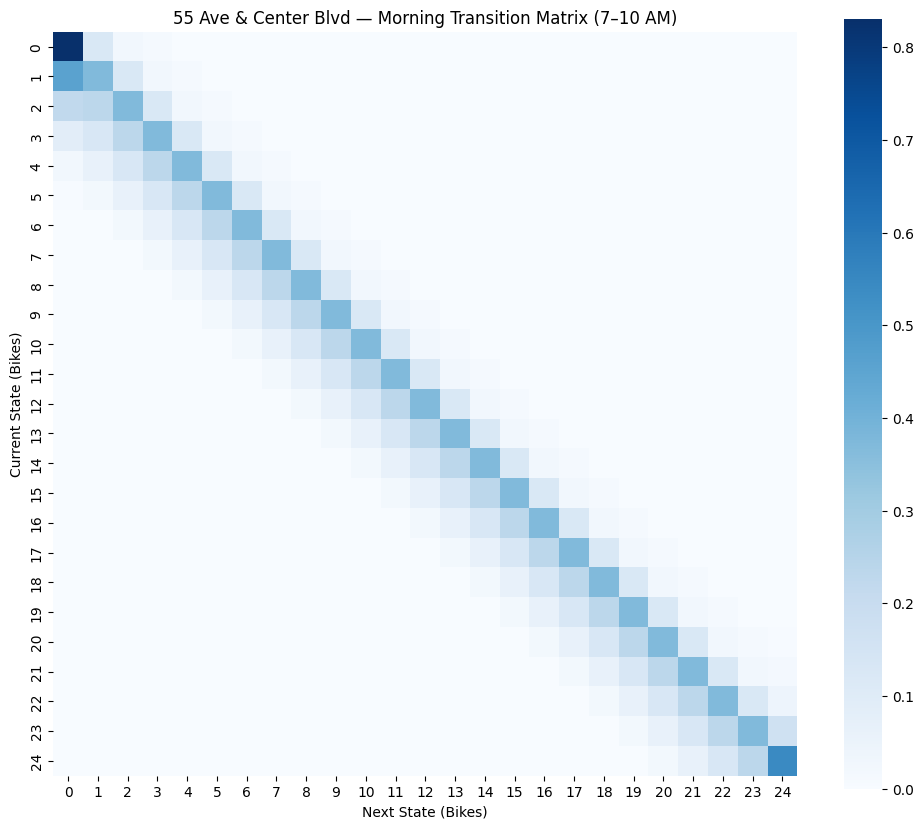

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

sns.heatmap(P, cmap="Blues", square=True)

plt.title("55 Ave & Center Blvd — Morning Transition Matrix (7–10 AM)")
plt.xlabel("Next State (Bikes)")
plt.ylabel("Current State (Bikes)")
plt.show()

#### 55 Ave & Center Blvd: evening (4–7pm)

In [34]:
transition_matrix_55_ave_evening_block = transition_matrix_construction(df_clean, "55 Ave & Center Blvd", start_hour=16, end_hour=19)
P = pd.DataFrame(transition_matrix_55_ave_evening_block)

P.index.name = "Current State"
P.columns.name = "Next State"

display(P.round(3))

Next State,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
Current State,,,,,,,,,,,,,,,,,,,,,
0,0.595,0.183,0.098,0.082,0.019,0.013,0.008,0.003,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.347,0.249,0.183,0.098,0.082,0.019,0.013,0.008,0.003,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,0.161,0.185,0.249,0.183,0.098,0.082,0.019,0.013,0.008,0.003,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,0.063,0.098,0.185,0.249,0.183,0.098,0.082,0.019,0.013,0.008,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,0.026,0.037,0.098,0.185,0.249,0.183,0.098,0.082,0.019,0.013,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
5,0.011,0.016,0.037,0.098,0.185,0.249,0.183,0.098,0.082,0.019,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
6,0.005,0.005,0.016,0.037,0.098,0.185,0.249,0.183,0.098,0.082,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
7,0.000,0.005,0.005,0.016,0.037,0.098,0.185,0.249,0.183,0.098,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
8,0.000,0.000,0.005,0.005,0.016,0.037,0.098,0.185,0.249,0.183,...,0.003,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


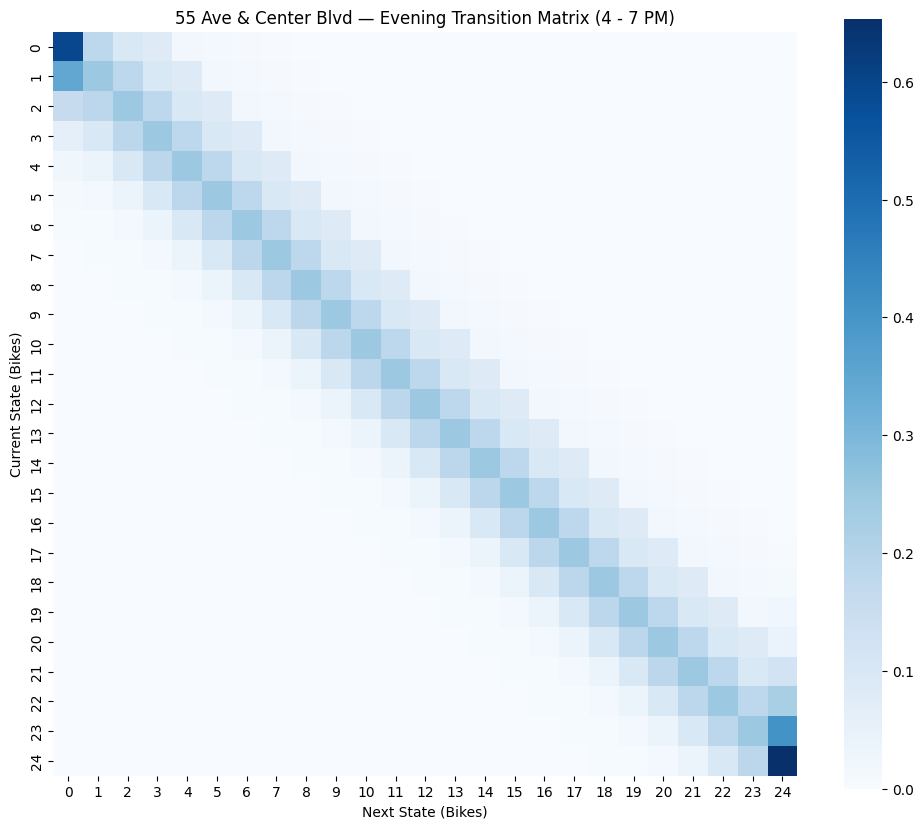

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

sns.heatmap(P, cmap="Blues", square=True)

plt.title("55 Ave & Center Blvd — Evening Transition Matrix (4 - 7 PM)")
plt.xlabel("Next State (Bikes)")
plt.ylabel("Current State (Bikes)")
plt.show()

#### Roosevelt Island Tramway: morning (7–10am)

In [36]:
transition_matrix_roosevelt_morning_block = transition_matrix_construction(df_clean, "Roosevelt Island Tramway", start_hour=7, end_hour=10)
P = pd.DataFrame(transition_matrix_roosevelt_morning_block)

P.index.name = "Current State"
P.columns.name = "Next State"

display(P.round(3))

Next State,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
Current State,,,,,,,,,,,,,,,,,,,,,
0,0.730,0.206,0.050,0.008,0.005,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.153,0.577,0.206,0.050,0.008,0.005,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,0.024,0.130,0.577,0.206,0.050,0.008,0.005,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,0.000,0.024,0.130,0.577,0.206,0.050,0.008,0.005,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,0.000,0.000,0.024,0.130,0.577,0.206,0.050,0.008,0.005,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
5,0.000,0.000,0.000,0.024,0.130,0.577,0.206,0.050,0.008,0.005,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
6,0.000,0.000,0.000,0.000,0.024,0.130,0.577,0.206,0.050,0.008,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
7,0.000,0.000,0.000,0.000,0.000,0.024,0.130,0.577,0.206,0.050,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
8,0.000,0.000,0.000,0.000,0.000,0.000,0.024,0.130,0.577,0.206,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


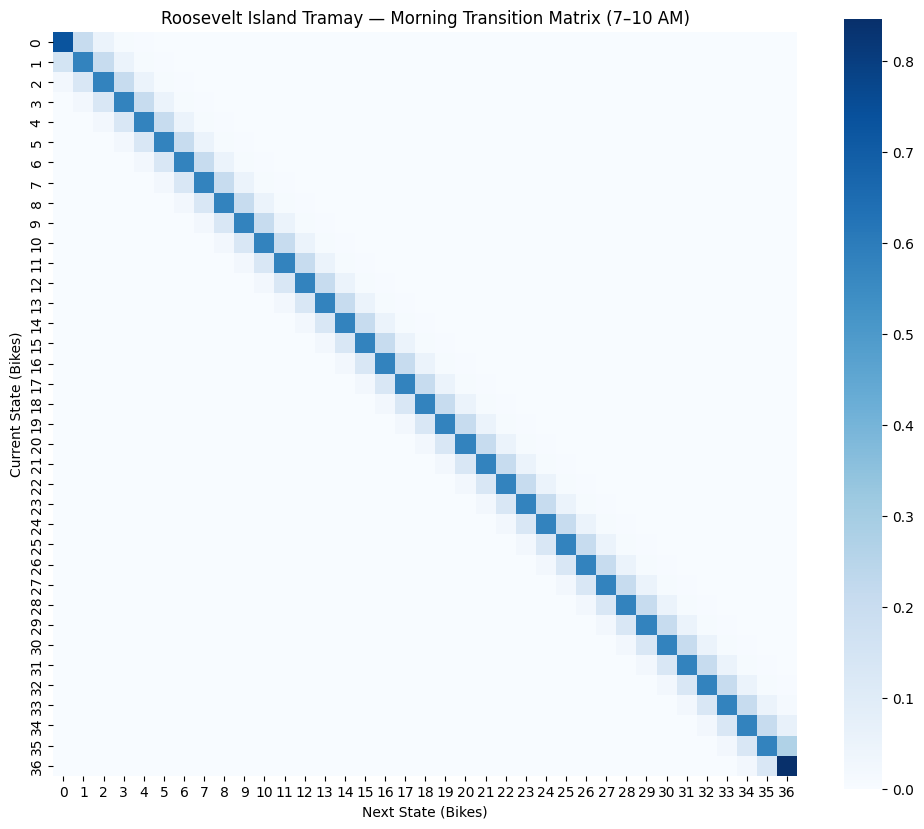

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

sns.heatmap(P, cmap="Blues", square=True)

plt.title("Roosevelt Island Tramay — Morning Transition Matrix (7–10 AM)")
plt.xlabel("Next State (Bikes)")
plt.ylabel("Current State (Bikes)")
plt.show()

#### Roosevelt Island Tramway: evening (4–7pm)

In [38]:
transition_matrix_roosevelt_evening_block = transition_matrix_construction(df_clean, "Roosevelt Island Tramway", start_hour=16, end_hour=19)
P = pd.DataFrame(transition_matrix_roosevelt_evening_block)

P.index.name = "Current State"
P.columns.name = "Next State"

display(P.round(3))

Next State,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
Current State,,,,,,,,,,,,,,,,,,,,,
0,0.704,0.124,0.071,0.045,0.032,0.011,0.011,0.003,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.362,0.341,0.124,0.071,0.045,0.032,0.011,0.011,0.003,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,0.196,0.167,0.341,0.124,0.071,0.045,0.032,0.011,0.011,0.003,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,0.082,0.114,0.167,0.341,0.124,0.071,0.045,0.032,0.011,0.011,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,0.042,0.040,0.114,0.167,0.341,0.124,0.071,0.045,0.032,0.011,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
5,0.024,0.019,0.040,0.114,0.167,0.341,0.124,0.071,0.045,0.032,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
6,0.016,0.008,0.019,0.040,0.114,0.167,0.341,0.124,0.071,0.045,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
7,0.008,0.008,0.008,0.019,0.040,0.114,0.167,0.341,0.124,0.071,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
8,0.003,0.005,0.008,0.008,0.019,0.040,0.114,0.167,0.341,0.124,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


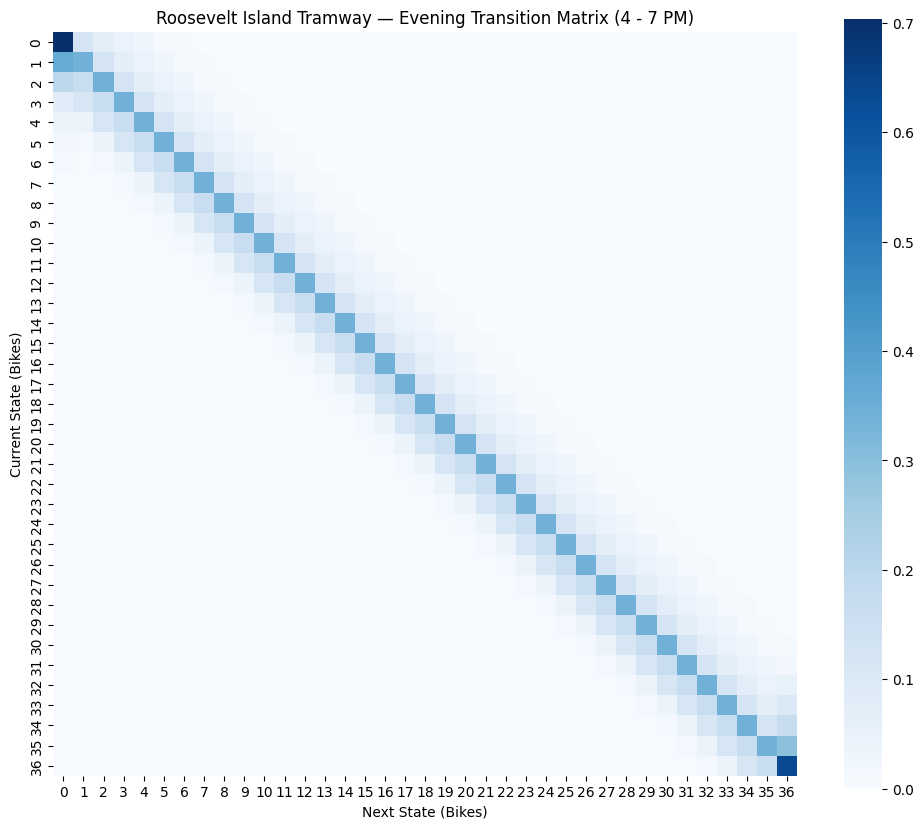

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

sns.heatmap(P, cmap="Blues", square=True)

plt.title("Roosevelt Island Tramway — Evening Transition Matrix (4 - 7 PM)")
plt.xlabel("Next State (Bikes)")
plt.ylabel("Current State (Bikes)")
plt.show()

## 4. How Each Transition Matrix Is Calculated
We chose **three stations** and **two weekday time blocks**, giving **6 transition matrices** (one per station × block):

| Station | Capacity $C$ (docks) | States |
|---|---:|---|
| 7 Ave & Central Park South | 70 | $\{0, 1, \ldots, 70\}$ |
| 55 Ave & Center Blvd | 24 | $\{0, 1, \ldots, 24\}$ |
| Roosevelt Island Tramway | 36 | $\{0, 1, \ldots, 36\}$ |

- **Morning:** 7am–10am, **Evening:** 4pm–7pm, on all 21 weekdays in August 2026.
- **Time step:** 10 minutes, so each block has 18 steps per day and $21 \times 18 = 378$ windows in total.
- **State:** the number of bikes at the station.

### Step 1: Net change in each 10-minute window
For every 10-minute window $w$ in the block, we count the trips that **ended** at the station during $w$ (returns) and the trips that **started** there during $w$ (rentals):

$$N_w = \#\text{returns in } w - \#\text{rentals in } w$$

Windows where nothing happened get $N_w = 0$.

### Step 2: Probability of each net change
To calculate the probabilities, we look at the **number of 10-minute windows with net change $k$** (numerator) divided by the **total number of 10-minute windows in the time block** (denominator, 378, including the quiet windows):

$$p(k) = \frac{\#\{\text{windows } w : N_w = k\}}{378}$$

### Step 3: Transition probabilities
Moving from $i$ bikes to $j$ bikes requires a net change of $j - i$. The station can't go below 0 bikes or above $C$, so any net change that would push past those limits is counted as landing on 0 or $C$:

$$
P_{ij} =
\begin{cases}
\displaystyle\sum_{k \le -i} p(k) & j = 0 \quad \text{(station empties)} \\[6pt]
p(j - i) & 0 < j < C \\[6pt]
\displaystyle\sum_{k \ge C - i} p(k) & j = C \quad \text{(station fills)}
\end{cases}
$$

Each row sums to 1. The six matrices use the same formula, so they differ only through their capacity $C$ and their net-change distribution $p(k)$.

### Worked example: Roosevelt Island Tramway, morning ($C = 36$)
| Net change $k$ | −2 | −1 | 0 | +1 | +2 | +3 | +4 | Total |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| # windows | 9 | 49 | 218 | 78 | 19 | 3 | 2 | 378 |
| $p(k)$ | 0.024 | 0.130 | 0.577 | 0.206 | 0.050 | 0.008 | 0.005 | 1 |

- **Interior:** $P_{18,19} = p(+1) = 78/378 = 0.206$
- **Empty boundary:** $P_{0,0} = p(-2) + p(-1) + p(0) = (9 + 49 + 218)/378 = 276/378 = 0.730$
- **Full boundary:** $P_{35,36} = p(\ge +1) = (78 + 19 + 3 + 2)/378 = 102/378 = 0.270$


### 4.1 How the matrices differ across stations and time blocks
All six matrices follow the same formula, so they differ only through each station's capacity $C$ and its net-change distribution $p(k)$. We compare them in three ways: drift, activity level, and the size of swings relative to capacity.

| Station | Block | $C$ | Expected net change | $P(\text{no change})$ | $P(\lvert k \rvert \ge 5)$ |
|---|---|---:|---:|---:|---:|
| 7 Ave & Central Park S | Morning | 70 | +1.12 | 0.14 | 0.16 |
| 7 Ave & Central Park S | Evening | 70 | −1.34 | 0.13 | 0.31 |
| 55 Ave & Center Blvd | Morning | 24 | −0.56 | 0.37 | 0.01 |
| 55 Ave & Center Blvd | Evening | 24 | +0.22 | 0.25 | 0.03 |
| Roosevelt Island Tramway | Morning | 36 | +0.17 | 0.58 | 0.00 |
| Roosevelt Island Tramway | Evening | 36 | −0.07 | 0.34 | 0.05 |

**How each metric is calculated.** All three metrics come from the 378 ten-minute windows in each station × block, where $N_w$ is the net change (returns − rentals) in window $w$ and $p(k)$ is the probability of net change $k$ (section 4, Step 2).
- **Mean net change** (average bikes gained per 10-minute step; positive = filling up, negative = emptying):
$$\bar{N} = \frac{1}{378}\sum_{w} N_w = \sum_k k \, p(k)$$
- **$P(\text{no change})$** (share of windows where the bike count stayed the same; this is the diagonal entry $P_{ii}$ for any state away from 0 and $C$):
$$P(\text{no change}) = p(0) = \frac{\#\{w : N_w = 0\}}{378}$$
- **$P(\lvert k \rvert \ge 5)$** (share of windows with a swing of 5 or more bikes in either direction):
$$P(\lvert k \rvert \ge 5) = \sum_{k \le -5} p(k) + \sum_{k \ge 5} p(k) = \frac{\#\{w : \lvert N_w \rvert \ge 5\}}{378}$$

**Example: Roosevelt Island Tramway, morning.** Using the window counts from section 4 (−2: 9, −1: 49, 0: 218, +1: 78, +2: 19, +3: 3, +4: 2):
- Mean: $\dfrac{(-2)(9) + (-1)(49) + 0(218) + 1(78) + 2(19) + 3(3) + 4(2)}{378} = \dfrac{66}{378} = +0.17$
- $P(\text{no change}) = 218/378 = 0.58$
- $P(\lvert k \rvert \ge 5) = 0/378 = 0$ (no window changed by more than 4 bikes)

**Drift.** The mean net change shows which way each station tends to move, which in the matrix is whether each row's probability sits to the right of the diagonal (gaining bikes) or to the left (losing bikes).
- **7 Ave & Central Park South** fills up in the morning (+1.12 bikes per 10 minutes) and empties in the evening (−1.34), the strongest drift of any station. It sits on the south edge of Central Park, next to Midtown offices and hotels, so riders arrive in the morning and leave from it in the evening.
- **55 Ave & Center Blvd** does the opposite: it empties in the morning (−0.56) and refills slightly in the evening (+0.22). It is in a mostly residential part of Long Island City, so residents ride away in the morning (e.g. toward the subway or ferry) and return in the evening.
- **Roosevelt Island Tramway** is close to balanced in both blocks (+0.17 and −0.07), so its matrices are centered almost on the diagonal.

**Activity level.** $P(\text{no change})$ is the weight on the diagonal of each matrix, i.e. how often the station stays where it is for 10 minutes.
- Central Park South is by far the busiest station: the bike count changes in about 86–87% of 10-minute windows in both blocks.
- Roosevelt Island is the quietest, especially in the morning, when nothing changes in 58% of windows.
- At 55 Ave and Roosevelt Island, the evening is noticeably busier than the morning (no-change probability drops from 0.37 to 0.25 and from 0.58 to 0.34).

**Swings relative to capacity.** Large swings make the band around the diagonal wider and push more probability into the first column (station empties) and last column (station fills).
- Central Park South has the largest swings: in the evening, 31% of windows change by 5 or more bikes, and 21% lose 5 or more. Its large capacity (70 docks) absorbs much of this, since a 5-bike swing is only 7% of the station.
- 55 Ave rarely swings by 5 or more bikes (1–3% of windows), but it has the smallest capacity (24 docks), so its steady morning drift of −0.56 bikes per step matters more relative to its size.
- Roosevelt Island has small, rare swings (none of 5 or more in the morning) and a moderate capacity (36), so its matrices put very little weight on the empty and full columns.


In [40]:
# Compute the metrics used in section 4.1 for each station x time block
BLOCK_HOURS = {"Morning": (7, 10), "Evening": (16, 19)}

rows = []
for station, C in STATION_CAPACITY.items():
    for block, (h0, h1) in BLOCK_HOURS.items():
        N = station_net_change_v2(df_clean, station, start_hour=h0, end_hour=h1)  # net change per 10-min window
        rows.append({
            "station": station,
            "block": block,
            "C": C,
            "windows": len(N),
            "mean net change": N.mean(),
            "P(no change)": (N == 0).mean(),
            "P(any change)": (N != 0).mean(),
            "P(|k| >= 5)": (N.abs() >= 5).mean(),
            "P(k <= -5)": (N <= -5).mean(),
            "P(k >= +5)": (N >= 5).mean(),
        })

metrics_41 = pd.DataFrame(rows).set_index(["station", "block"])
display(metrics_41.round(3))

# # Worked example from the markdown: Roosevelt Island Tramway, morning
# N = station_net_change_v2(df_clean, "Roosevelt Island Tramway", start_hour=7, end_hour=10)
# counts = N.value_counts().sort_index()
# print("Roosevelt Island Tramway, morning: windows per net change")
# print(counts.to_string())
# print(f"Mean = {(counts.index * counts).sum()} / {counts.sum()} = {N.mean():+.2f}")
# print(f"P(no change) = {counts.get(0, 0)} / {counts.sum()} = {(N == 0).mean():.2f}")
# print(f"P(|k| >= 5) = {(N.abs() >= 5).sum()} / {counts.sum()} = {(N.abs() >= 5).mean():.2f}")


C  windows  mean net change  \
station                    block                                   
7 Ave & Central Park South Morning  70      378            1.116   
                           Evening  70      378           -1.344   
55 Ave & Center Blvd       Morning  24      378           -0.561   
                           Evening  24      378            0.217   
Roosevelt Island Tramway   Morning  36      378            0.175   
                           Evening  36      378           -0.069   

                                    P(no change)  P(any change)  P(|k| >= 5)  \
station                    block                                               
7 Ave & Central Park South Morning         0.143          0.857        0.156   
                           Evening         0.130          0.870        0.315   
55 Ave & Center Blvd       Morning         0.373          0.627        0.008   
                           Evening         0.249          0.751        0.034   
Roosevelt Island Tramway   Morning         0.577          0.423        0.000   
                           Evening         0.341          0.659        0.048   

                                    P(k <= -5)  P(k >= +5)  
station                    block                            
7 Ave & Central Park South Morning       0.042       0.114  
                           Evening       0.206       0.108  
55 Ave & Center Blvd       Morning       0.005       0.003  
                           Evening       0.011       0.024  
Roosevelt Island Tramway   Morning       0.000       0.000  
                           Evening       0.024       0.024

## 5. Stationary Distributions
A **stationary distribution** is a vector $\pi = (\pi_0, \pi_1, \ldots, \pi_C)$ that shows the **long-run fraction of time** the chain spends in each state. For our stations, $\pi_i$ is the share of 10-minute steps the station would have exactly $i$ bikes if the time block's conditions continued indefinitely (e.g. $\pi_0 = 0.34$ means the station is empty about 34% of the time). It is a probability distribution, so $\pi_i \ge 0$ and $\sum_i \pi_i = 1$.

It is called *stationary* because one step of the chain leaves it unchanged:

$$\pi P = \pi$$

We compute $\pi$ for each of the 6 chains by solving this linear system together with $\sum_i \pi_i = 1$.

**Our six chains are irreducible.** In all six station × time blocks, there were 10-minute windows with a net change of exactly $+1$ and windows with a net change of exactly $-1$, so $p(+1) > 0$ and $p(-1) > 0$:

| Station | Block | $p(+1)$ | $p(-1)$ |
|---|---|---:|---:|
| 7 Ave & Central Park S | Morning | 50/378 = 0.132 | 44/378 = 0.116 |
| 7 Ave & Central Park S | Evening | 30/378 = 0.079 | 34/378 = 0.090 |
| 55 Ave & Center Blvd | Morning | 47/378 = 0.124 | 89/378 = 0.235 |
| 55 Ave & Center Blvd | Evening | 69/378 = 0.183 | 70/378 = 0.185 |
| Roosevelt Island Tramway | Morning | 78/378 = 0.206 | 49/378 = 0.130 |
| Roosevelt Island Tramway | Evening | 47/378 = 0.124 | 63/378 = 0.167 |

This means that from any state $i$, the chain can move **up one bike** ($P_{i,i+1} = p(+1) > 0$ for $i < C$, including from empty) and **down one bike** ($P_{i,i-1} = p(-1) > 0$ for $i > 0$, including from full). Moving one bike at a time, the chain can get from any number of bikes $i$ to any other number $j$ with positive probability, so every state can reach every other state and each chain is irreducible. Therefore each chain has a **unique** stationary distribution.


In [41]:
n = P.shape[0]                                    # number of states (C + 1) 37
A = np.vstack([(P - np.eye(n)).T, np.ones(n)])    # balance equations + a row of 1s
b = np.zeros(n + 1)                               # 0 for each balance equation...
b[-1] = 1                                         # ...and 1 for the "sums to 1" equation
pi = np.linalg.lstsq(A, b, rcond=None)[0]         #
b

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 1.])

In [42]:
import numpy as np

# Step 1: put the six transition matrices in one dictionary
transition_matrices = {
    ("7 Ave & Central Park South", "Morning"): transition_matrix_central_park_morning_block,
    ("7 Ave & Central Park South", "Evening"): transition_matrix_central_park_evening_block,
    ("55 Ave & Center Blvd", "Morning"):       transition_matrix_55_ave_morning_block,
    ("55 Ave & Center Blvd", "Evening"):       transition_matrix_55_ave_evening_block,
    ("Roosevelt Island Tramway", "Morning"):   transition_matrix_roosevelt_morning_block,
    ("Roosevelt Island Tramway", "Evening"):   transition_matrix_roosevelt_evening_block,
}

# Step 2: solve pi P = pi together with sum(pi) = 1
def stationary_distribution(P):
    n = P.shape[0]                                    # number of states (C + 1)
    A = np.vstack([(P - np.eye(n)).T, np.ones(n)])    # balance equations + a row of 1s
    b = np.zeros(n + 1)                               # 0 for each balance equation...
    b[-1] = 1                                         # ...and 1 for the "sums to 1" equation
    pi = np.linalg.lstsq(A, b, rcond=None)[0]         # solve A pi = b
    return pi

# Step 3: compute pi for each station x time block
stationary = {}
for (station, block), P in transition_matrices.items():
    stationary[(station, block)] = stationary_distribution(P)


In [43]:
# Print the stationary distribution vector pi = (pi_0, pi_1, ..., pi_C) for each station x time block
np.set_printoptions(precision=4, suppress=True, linewidth=110)   # 4 decimals, no scientific notation

for (station, block), pi in stationary.items():
    print(f"{station}, {block} (C = {len(pi) - 1}, {len(pi)} states)")
    print(pi)
    print()

7 Ave & Central Park South, Morning (C = 70, 71 states)
[0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
 0.0001 0.0001 0.0001 0.0001 0.0001 0.0001 0.0002 0.0002 0.0003 0.0003 0.0004 0.0005 0.0006 0.0007 0.0008
 0.001  0.0012 0.0015 0.0018 0.0022 0.0027 0.0033 0.004  0.0049 0.0059 0.0072 0.0088 0.0106 0.0129 0.0157
 0.019  0.0238 0.0282 0.0341 0.0407 0.0518 0.0593 0.0706 0.078  0.0935 0.4125]

7 Ave & Central Park South, Evening (C = 70, 71 states)
[0.343  0.0565 0.0554 0.0475 0.0476 0.0446 0.0431 0.0346 0.0307 0.0302 0.0257 0.0245 0.0217 0.0208 0.0174
 0.0158 0.0141 0.0128 0.0115 0.0104 0.0093 0.0084 0.0075 0.0068 0.0061 0.0055 0.0049 0.0044 0.004  0.0036
 0.0032 0.0029 0.0026 0.0024 0.0021 0.0019 0.0017 0.0015 0.0014 0.0012 0.0011 0.001  0.0009 0.0008 0.0007
 0.0007 0.0006 0.0005 0.0005 0.0004 0.0004 0.0003 0.0003 0.0003 0.0003 0.0

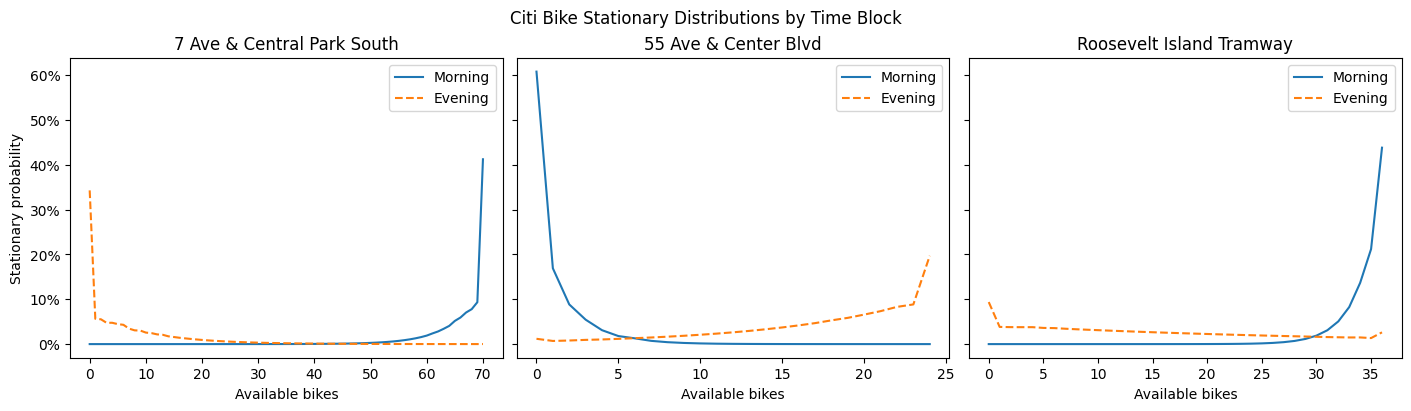

In [44]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

stations = list(dict.fromkeys(station for station, _ in stationary))

fig, axes = plt.subplots(
    1, len(stations), figsize=(14, 4), sharey=True,
    squeeze=False, layout="constrained"
)

for ax, station in zip(axes[0], stations):
    for block, linestyle in [("Morning", "-"), ("Evening", "--")]:
        pi = stationary[(station, block)]
        ax.plot(range(len(pi)), pi, linestyle=linestyle, label=block)

    ax.set_title(station)
    ax.set_xlabel("Available bikes")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.legend()

axes[0, 0].set_ylabel("Stationary probability")
fig.suptitle("Citi Bike Stationary Distributions by Time Block")
plt.show()

Open: 

- Do the stationary distributions exist and are they unique?

- How to interpret the stationary distributions?

## To Confirm we have stationary distirbution and they are unique we need to prove two thinks, we have an irreducible matrix and they are aperiodic

One way to do this is to transform our matrix into a graph, and then running bfs both fowards and backwards and see if the vertex we go through matches how many states we have if they do yayyy we proved irreducivle meaning every node can communicate with each other

In [45]:
class node:
    def __init__(self,name):
        self.name = name
        self.neighbors = []

    def add(self, node):
        self.neighbors.append(node.name)

    def __str__(self):
        return str(self.neighbors)


In [53]:
def make_graph(mat):
    nodes = []
    n = len(mat)

    for i in range(n):
        nodes.append(node(i))

    for i in range(n):
        for j in range(n):
            if mat[i][j] > 0:
                nodes[i].add(nodes[j])
        
    return nodes

mat = transition_matrix_roosevelt_evening_block
graph = make_graph(mat)
for state in graph:
    print(f"State {state.name} → {state}")

State 0 → [0, 1, 2, 3, 4, 5, 6, 7]
State 1 → [0, 1, 2, 3, 4, 5, 6, 7, 8]
State 2 → [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
State 3 → [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
State 4 → [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
State 5 → [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
State 6 → [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
State 7 → [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
State 8 → [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
State 9 → [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
State 10 → [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
State 11 → [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
State 12 → [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
State 13 → [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
State 14 → [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
State 15 → [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
State 16 → [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 2

Now that we made graph its time to run dfs, we can also just look at it and just by that ik its unreducible

In [ ]:
from collections import deque
def bfs(graph,start_name):
    visited = set([start_name])
    queue = deque([start_name])

    while queue:
        current_name = queue.popleft()
        for neighbor in graph[current_name].neighbors:
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)
    return visited


def is_irreducible(mat):
    n = len(mat)
    foward_graph = make_graph(mat)
    if n != len(bfs(foward_graph,0)):
        return False
    
    backward_graph = make_graph(mat.T)
    if n != len(bfs(backward_graph,0)):
        return False

    return True

In [77]:
import numpy as np
import matplotlib.pyplot as plt

def simulate(mat, station_name, n=18, m=1000, start=None, plot=True):
      capacity = len(mat) - 1
      if start is None:
            start = capacity // 2

      time_average = np.zeros(m)
      hit_zero = np.zeros(m, dtype=bool)
      hit_full = np.zeros(m, dtype=bool)

      if plot:
            fig, ax = plt.subplots()

      for i in range(m):
            states = np.zeros(n + 1, dtype=int)
            states[0] = start

            for j in range(1, n + 1):
                  states[j] = np.random.choice(len(mat), p=mat[states[j - 1]])

            time_average[i] = states[:n].mean()    # X_0 through X_(n-1)
            hit_zero[i] = (states[1:] == 0).any()  # X_1 through X_n
            hit_full[i] = (states[1:] == capacity).any()

            if plot and i < 5:
                  ax.step(10 * np.arange(n + 1), states, where="post", alpha=0.7)

      if plot:
            ax.set(title=station_name, xlabel="Minutes elapsed", ylabel="Available bikes")
            plt.show()

      print("Average_bikes",time_average.mean())
      print("Empty_risk",hit_zero.mean())
      print("Full_risk",hit_full.mean())

      return {
            "average_bikes": time_average.mean(),
            "empty_risk": hit_zero.mean(),
            "full_risk": hit_full.mean(),
      }

## Part 2 Simulations

#### 7 Ave & Central Park South: morning (7–10am)

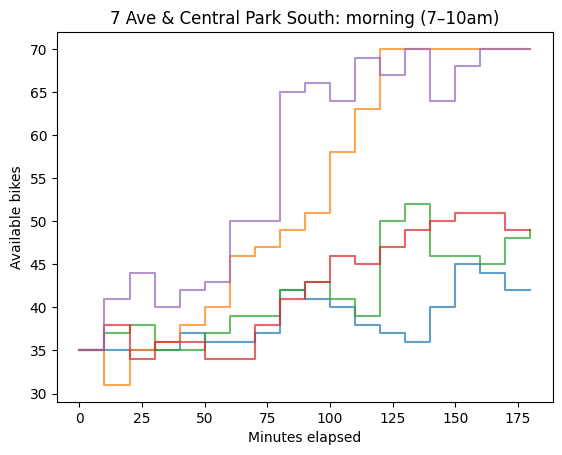

Average_bikes 44.10333333333334
Empty_risk 0.0
Full_risk 0.22


In [79]:
_ = simulate(transition_matrix_central_park_morning_block,"7 Ave & Central Park South: morning (7–10am)")

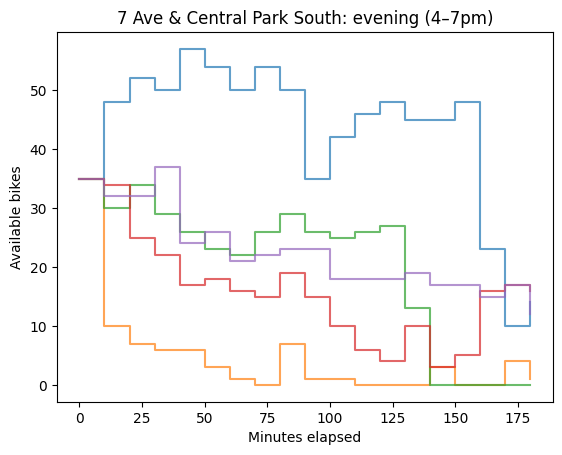

Average_bikes 24.468944444444446
Empty_risk 0.39
Full_risk 0.005


In [80]:
_ = simulate(transition_matrix_central_park_evening_block,"7 Ave & Central Park South: evening (4–7pm)")

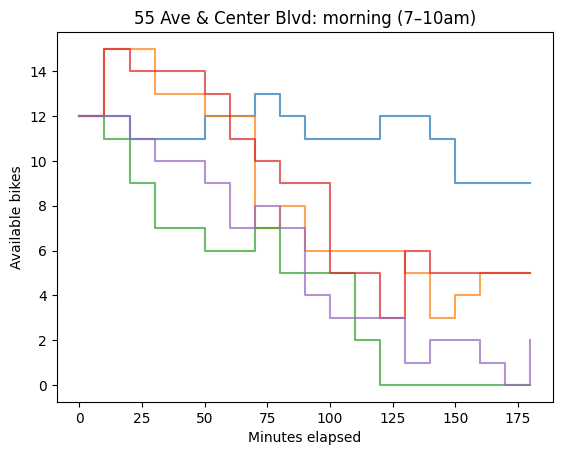

Average_bikes 7.475222222222222
Empty_risk 0.444
Full_risk 0.0


In [82]:
_ = simulate(transition_matrix_55_ave_morning_block,"55 Ave & Center Blvd: morning (7–10am)")

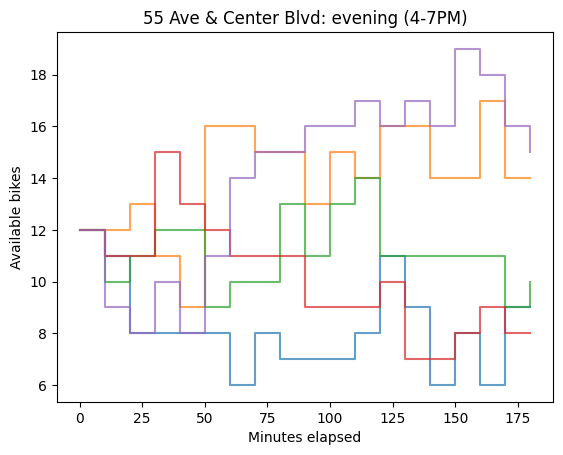

Average_bikes 13.52211111111111
Empty_risk 0.06
Full_risk 0.243


In [83]:
_ = simulate(transition_matrix_55_ave_evening_block,"55 Ave & Center Blvd: evening (4-7PM)")

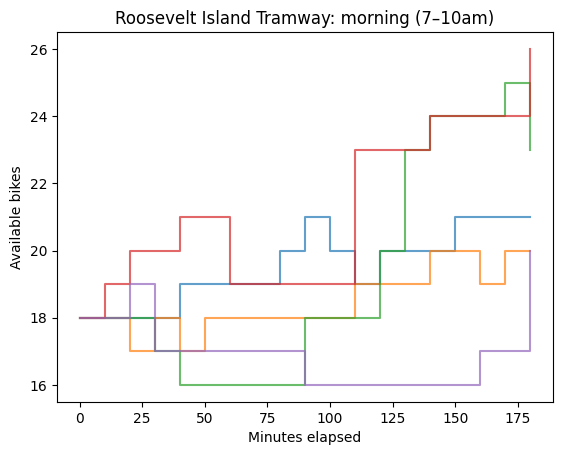

Average_bikes 19.490277777777777
Empty_risk 0.0
Full_risk 0.0


In [84]:
_ = simulate(transition_matrix_roosevelt_morning_block,"Roosevelt Island Tramway: morning (7–10am)")

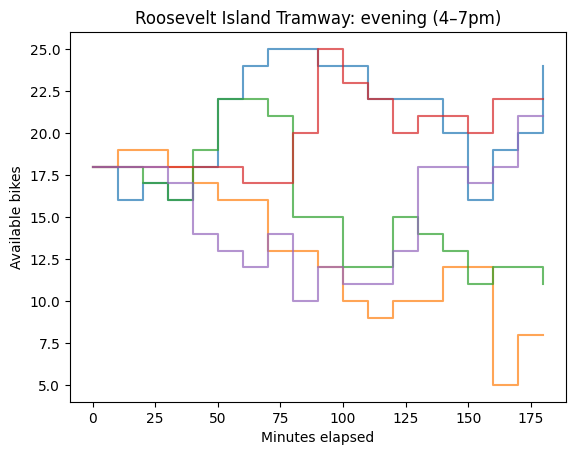

Average_bikes 17.501
Empty_risk 0.038
Full_risk 0.025


In [85]:
_ = simulate(transition_matrix_roosevelt_evening_block,"Roosevelt Island Tramway: evening (4–7pm)")

Part2 Test

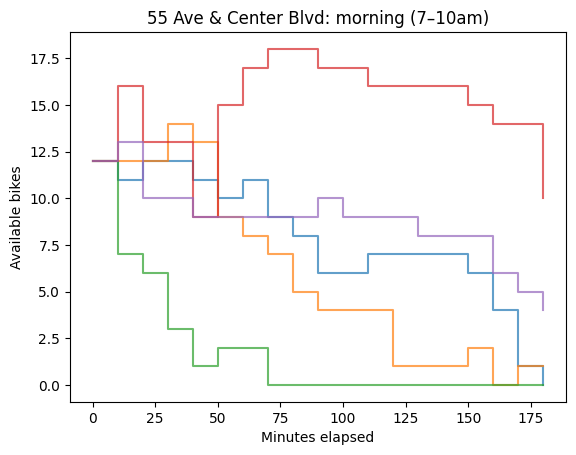

Average_bikes 7.658
Empty_risk 0.438
Full_risk 0.001


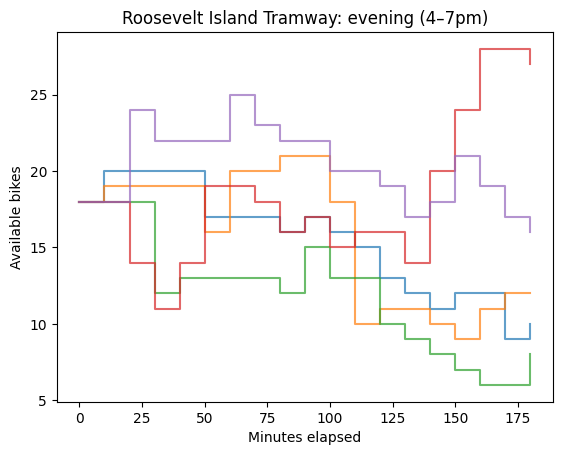

Average_bikes 17.451333333333334
Empty_risk 0.05
Full_risk 0.033


In [89]:
central_station_baseline = simulate(transition_matrix_55_ave_morning_block,"55 Ave & Center Blvd: morning (7–10am)")
roosevelt_station_baseline = simulate(transition_matrix_roosevelt_evening_block,"Roosevelt Island Tramway: evening (4–7pm)")

In [92]:
central_station_baseline

{'average_bikes': 7.658, 'empty_risk': 0.438, 'full_risk': 0.001}

In [93]:
roosevelt_station_baseline

{'average_bikes': 17.451333333333334, 'empty_risk': 0.05, 'full_risk': 0.033}

In [ ]:
def simulate(mat, station_name, n=18, m=1000, start=None, plot=True):


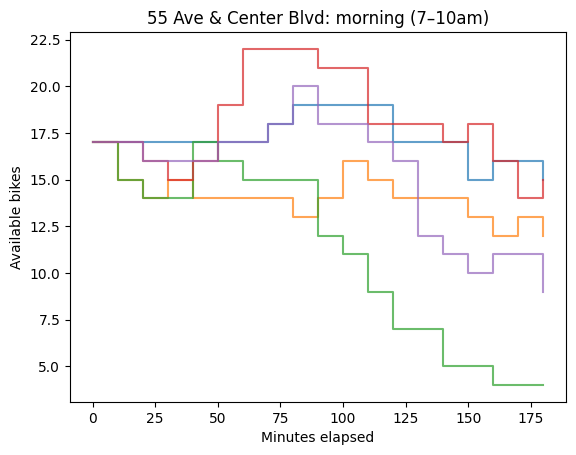

Average_bikes 12.142777777777777
Empty_risk 0.16
Full_risk 0.013


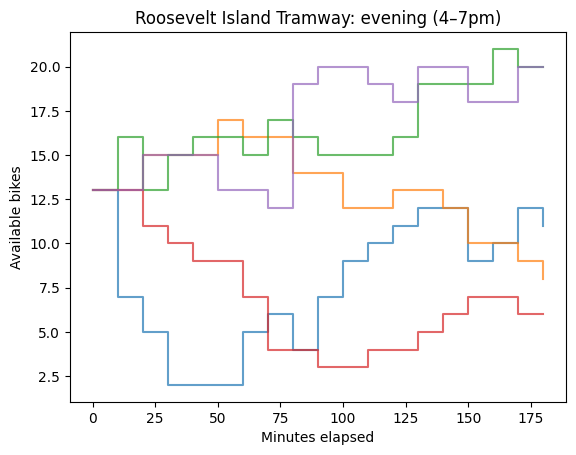

Average_bikes 12.593
Empty_risk 0.124
Full_risk 0.008


In [94]:
size1 = (len(transition_matrix_55_ave_morning_block)-1)//2
size2 = (len(transition_matrix_roosevelt_evening_block)-1)//2
central_station_baseline = simulate(transition_matrix_55_ave_morning_block, "55 Ave & Center Blvd: morning (7–10am)",start = size1 +5)
roosevelt_station_baseline = simulate(transition_matrix_roosevelt_evening_block,"Roosevelt Island Tramway: evening (4–7pm)",start = size2-5)